# REINFORCE demo

## Instructions

1. Follow the instructions below to construct and optimize the policy.
2. Run all the cells before submitting.
3. Submit your notebook in Gradescope.


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import torch

## Previously, in another AI Course...

STATE 0
```
🐱🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🐟🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨🪨
```

## Cat State

The cats have the same four actions as before, but now have continuous positions and velocities.
Additionally, the velocity is capped at one and the position updates are noisy.

In [13]:
# DO NOT CHANGE

CAT_ACTIONS = {"up": (0, 1), "down" : (0, -1), "left" : (-1, 0), "right": (1, 0)}

class CatState:
    def __init__(self, x, y, vx, vy):
        self.x = x
        self.y = y
        self.vx = vx
        self.vy = vy

    def __repr__(self):
        d = self.distance_to_fish()
        return f"CatState(x={self.x:+.2f}, y={self.y:+.2f}, vx={self.vx:+.2f}, vy={self.vy:+.2f}, distance to fish={d:.2f})"

    def act(self, action):
        dvx, dvy = CAT_ACTIONS[action]

        new_vx = self.vx + dvx
        new_vy = self.vy + dvy
        v = np.sqrt(new_vx**2 + new_vy**2)

        if v > 1:
            new_vx /= v
            new_vy /= v

        new_x = self.x + self.vx + np.random.normal(0, 0.1)
        new_y = self.y + self.vy + np.random.normal(0, 0.1)

        new_state = CatState(new_x, new_y, new_vx, new_vy)

        reward = 1 if self.distance_to_fish() <= 5 else 0

        return (reward, new_state)

    def distance_to_fish(self):
        return np.sqrt((self.x-8)**2 + (self.y - 0)**2)

c0 = CatState(0, 0, 0, 0)
c0

CatState(x=+0.00, y=+0.00, vx=+0.00, vy=+0.00, distance to fish=8.00)

### Uniform Random Cat Walks

Implement a function that uses the CatState class to simulate a uniform random policy (i.e. up/down/left/right with equal probability) for 100 steps and print the resulting actions and rewards.
Run the function twice showing the varying behavior.

In [14]:
# YOUR CHANGES HERE

s = c0
print(s)
for t in range(20):
    (r, s) = s.act(np.random.choice(list(CAT_ACTIONS.keys())))
    print("TIME", t, "REWARD", r, "STATE", s)

CatState(x=+0.00, y=+0.00, vx=+0.00, vy=+0.00, distance to fish=8.00)
TIME 0 REWARD 0 STATE CatState(x=-0.02, y=+0.01, vx=+0.00, vy=+1.00, distance to fish=8.02)
TIME 1 REWARD 0 STATE CatState(x=+0.03, y=+0.87, vx=+0.00, vy=+0.00, distance to fish=8.02)
TIME 2 REWARD 0 STATE CatState(x=+0.01, y=+0.77, vx=+0.00, vy=-1.00, distance to fish=8.02)
TIME 3 REWARD 0 STATE CatState(x=-0.09, y=-0.21, vx=-0.71, vy=-0.71, distance to fish=8.09)
TIME 4 REWARD 0 STATE CatState(x=-0.95, y=-1.03, vx=-0.38, vy=-0.92, distance to fish=9.01)
TIME 5 REWARD 0 STATE CatState(x=-1.33, y=-1.85, vx=-0.20, vy=-0.98, distance to fish=9.51)
TIME 6 REWARD 0 STATE CatState(x=-1.73, y=-2.81, vx=-0.10, vy=-1.00, distance to fish=10.13)
TIME 7 REWARD 0 STATE CatState(x=-1.86, y=-3.79, vx=-0.05, vy=-1.00, distance to fish=10.57)
TIME 8 REWARD 0 STATE CatState(x=-1.78, y=-4.80, vx=-0.02, vy=-1.00, distance to fish=10.89)
TIME 9 REWARD 0 STATE CatState(x=-1.96, y=-5.80, vx=-0.02, vy=+0.00, distance to fish=11.53)
TIME 1

## Optimize a Policy

You will optimize the following policy to maximize the cat's rewards.

In [15]:
# DO NOT CHANGE

CAT_ACTION_ORDER = ["up", "down", "left", "right"]

class ShallowPolicy(torch.nn.Module):
    def __init__(self, input_size=4, hidden_size=128, output_size=4):
        super().__init__()

        self.fc_1 = torch.nn.Linear(input_size, hidden_size)
        self.fc_2 = torch.nn.Linear(hidden_size, output_size)

        self.relu = torch.nn.ReLU()
        self.softmax = torch.nn.Softmax(dim=0)

    def forward(self, x):
        logits = self.fc_2(self.relu(self.fc_1(x)))
        # print("LOGITS", logits)
        return self.softmax(logits)

pi = ShallowPolicy()

### Construct input tensors.

Fill in the function below to construct an appropriate tensor from a cat state to pass into the policy.

In [16]:
# YOUR CHANGES HERE

def compute_state_tensor(s):
    return torch.tensor([s.x, s.y, s.vx, s.vy], dtype=torch.float32)

### Test your tensor conversion.

In [17]:
# DO NOT CHANGE

compute_state_tensor(c0)

tensor([0., 0., 0., 0.])

In [18]:
# DO NOT CHANGE

compute_state_tensor(CatState(1, 2, 3, 4))

tensor([1., 2., 3., 4.])

### Write a function using a policy to pick an action for the state.

In [20]:
def pick_action(policy, s):
    # YOUR CHANGES HERE
    action_probabilities = policy(compute_state_tensor(s))
    try:
        action_index = int(torch.multinomial(action_probabilities, 1))
    except:
        # debug function probabilities
        print(action_probabilities)
        raise

    return (action_index, CAT_ACTION_ORDER[action_index])

### Test picking actions

Use the policy `pi` to pick 10 actions starting from the initial state `c0`.

Log each action in the following format.
```
ACTION down STATE CatState(x=+0.09, y=+0.07, vx=+0.00, vy=-1.00, distance to fish=7.91)
```

In [21]:
# YOUR CHANGES HERE

s = c0
for _ in range(10):
    (i, a) = pick_action(pi, s)
    (r, s) = s.act(a)

    print("ACTION", a, "STATE", s)

ACTION right STATE CatState(x=+0.08, y=+0.03, vx=+1.00, vy=+0.00, distance to fish=7.92)
ACTION up STATE CatState(x=+1.01, y=+0.02, vx=+0.71, vy=+0.71, distance to fish=6.99)
ACTION right STATE CatState(x=+1.87, y=+0.68, vx=+0.92, vy=+0.38, distance to fish=6.16)
ACTION left STATE CatState(x=+2.93, y=+1.17, vx=-0.08, vy=+0.38, distance to fish=5.20)
ACTION left STATE CatState(x=+2.96, y=+1.53, vx=-0.94, vy=+0.34, distance to fish=5.27)
ACTION up STATE CatState(x=+2.06, y=+1.66, vx=-0.58, vy=+0.82, distance to fish=6.16)
ACTION up STATE CatState(x=+1.54, y=+2.32, vx=-0.30, vy=+0.95, distance to fish=6.86)
ACTION left STATE CatState(x=+1.23, y=+3.22, vx=-0.81, vy=+0.59, distance to fish=7.50)
ACTION up STATE CatState(x=+0.42, y=+3.88, vx=-0.45, vy=+0.89, distance to fish=8.52)
ACTION up STATE CatState(x=-0.00, y=+4.95, vx=-0.23, vy=+0.97, distance to fish=9.41)


## Implement the REINFORCE algorithm as covered in class.

Use 1000 episodes of 100 actions to train your policy to maximize total reward using the REINFORCE algorithm.
Save the total rewards for each episode to be plotted later.
Use $\gamma$ = 1.0 and $\alpha=0.001$.

During the REINFORCEMENT algorithm, if the selected action probability is zero, skip the parameter update.
This may happen due to parameter changes since the action was chosen.


In [23]:
# YOUR CHANGES HERE

num_actions = 100
alpha = 0.001

episode_rewards = []

for e in range(1000):
    states = [c0]
    action_indexes = []
    rewards = [None]
    for t in range(num_actions):
        with torch.no_grad():
            (i, a) = pick_action(pi, states[-1])
            (r, s) = states[-1].act(a)

            states.append(s)
            action_indexes.append(i)
            rewards.append(r)

    episode_rewards.append(sum(rewards[1:]))
    print("EPISODE", e, "REWARD", episode_rewards[-1])

    for t in range(num_actions):
        G_t = sum(rewards[t+1:])

        pi.train()
        probabilities = pi(compute_state_tensor(states[t]))
        action_probability = probabilities[action_indexes[t]]
        if action_probability <= 0:
            print("  SKIPPING ZERO PROBABILITY ACTION")
            continue

        log_prob = torch.log(action_probability)
        log_prob.backward() # gradient computation

        for p in pi.parameters():
            p.data += alpha * G_t * p.grad
            p.grad.data.zero_()


EPISODE 0 REWARD 0
EPISODE 1 REWARD 4
EPISODE 2 REWARD 0
EPISODE 3 REWARD 2
EPISODE 4 REWARD 0
EPISODE 5 REWARD 12
EPISODE 6 REWARD 8
EPISODE 7 REWARD 12
EPISODE 8 REWARD 20
EPISODE 9 REWARD 5
EPISODE 10 REWARD 20
EPISODE 11 REWARD 14
EPISODE 12 REWARD 29
EPISODE 13 REWARD 27
EPISODE 14 REWARD 24
EPISODE 15 REWARD 32
EPISODE 16 REWARD 37
EPISODE 17 REWARD 20
EPISODE 18 REWARD 16
EPISODE 19 REWARD 14
EPISODE 20 REWARD 25
EPISODE 21 REWARD 28
EPISODE 22 REWARD 28
EPISODE 23 REWARD 30
EPISODE 24 REWARD 56
EPISODE 25 REWARD 42
EPISODE 26 REWARD 55
EPISODE 27 REWARD 55
EPISODE 28 REWARD 69
EPISODE 29 REWARD 41
EPISODE 30 REWARD 72
EPISODE 31 REWARD 33
EPISODE 32 REWARD 34
EPISODE 33 REWARD 46
EPISODE 34 REWARD 36
EPISODE 35 REWARD 22
EPISODE 36 REWARD 20
EPISODE 37 REWARD 27
EPISODE 38 REWARD 17
EPISODE 39 REWARD 28
EPISODE 40 REWARD 23
EPISODE 41 REWARD 34
EPISODE 42 REWARD 30
EPISODE 43 REWARD 39
EPISODE 44 REWARD 40
EPISODE 45 REWARD 38
EPISODE 46 REWARD 52
EPISODE 47 REWARD 53
EPISODE 4

### Plot the rewards for each episode.

Use a scatter plot with appropriate alpha.

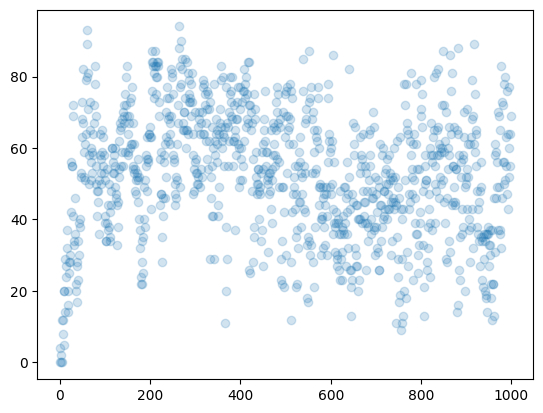

In [24]:
# YOUR CHANGES HERE

plt.scatter(range(1000), episode_rewards, alpha=0.2);